In [ ]:
from google.colab import files
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Step 1: Upload the CSV file
uploaded = files.upload()

Saving Standardized_Dataset.csv to Standardized_Dataset (2).csv


In [ ]:
import threading, time, sys

def keep_colab_alive(interval_sec=60):
    """Print a small heartbeat so Colab sees activity."""
    while True:
        # ‘flush’ forces the message to appear immediately
        print(f"⏰ still training {time.strftime('%H:%M:%S')}", flush=True)
        time.sleep(interval_sec)

# Start the daemon – it dies automatically when the notebook stops
threading.Thread(target=keep_colab_alive, daemon=True).start()

⏰ still training 14:37:13


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ========================= RL (CTDE, 3 agents: HVAC, Light, PV) =========================
import torch, torch.nn as nn, torch.nn.functional as F
from torch.distributions import Normal
import numpy as np, pandas as pd, random, matplotlib.pyplot as plt
from collections import deque, namedtuple
import os, glob

# ─────────────────────────── Checkpoint / Metrics dirs ──────────────────
DRIVE_ROOT = "/content/drive/MyDrive"
CKPT_DIR = os.path.join(DRIVE_ROOT, "checkpoints") if os.path.isdir(DRIVE_ROOT) else "./checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)
METRICS_LIVE = os.path.join(CKPT_DIR, "run_metrics_live.csv")
print("✔ Using checkpoint dir:", CKPT_DIR)

# ─────────────────────────── Hyper-parameters ───────────────────────────
TAU        = 0.01
GAMMA      = 0.99
ACTOR_LR   = 3e-4
CRITIC_LR  = 1e-3
ALPHA_LR   = 3e-4

NUM_EPISODES = 10
BATCH_SIZE   = 256
BUFFER_SIZE  = 100_000
ACTION_DIM   = 1
N_AGENTS     = 3  # HVAC, LIGHT, PV

HVAC_MIN, HVAC_MAX = 21.0, 25.0
PMV_MIN,  PMV_MAX  = -0.5, 0.5
EPS = 1e-6

# ─────────────── PV totals (kWh) & month filter ───────────────
PV_MONTHLY_KWH = {5: 2.09, 6: 2.17, 7: 2.09, 8: 1.98}
MONTHS_SUBSET  = [5, 6, 7, 8]

# Hourly shape (kW-like weights; will be normalized per day)
PV_HOURLY_SHAPE = {
    5: [0,0,0,0,0,0, 2.2,6.4,11.3,15.6,18.6,20.3,20.0,18.8,15.8,11.9,7.0,2.6,0.1,0,0,0,0,0],
    6: [0,0,0,0,0,0.1,2.4,6.5,11.4,15.8,18.8,20.6,20.7,19.4,16.6,12.6,7.6,3.1,0.7,0,0,0,0,0],
    7: [0,0,0,0,0,0, 1.9,5.8,10.6,14.9,18.1,19.8,20.0,18.9,16.4,12.5,7.7,3.2,0.7,0,0,0,0,0],
    8: [0,0,0,0,0,0, 1.5,5.2,10.1,14.3,17.9,19.5,19.5,18.4,15.3,11.5,6.9,2.6,0.1,0,0,0,0,0],
}

# ───────────── Battery pack (18 modules → 19 kWh, 309 Ah) ─────────────
BATT_CAP_KWH    = 19.0          # total energy
BATT_SOC_MAX    = 0.97
BATT_SOC_MIN    = 0.05
BATT_EFF_CH     = 0.95
BATT_EFF_DCH    = 0.95
# charge in ~7 h, discharge in ~4 h
BATT_MAX_C_RATE = 1.0 / 7.0     # ≈0.1429 C → 2.714 kWh/h limit from C-rate
BATT_MAX_D_RATE = 1.0 / 4.0     # 0.25  C   → 4.75  kWh/h limit from C-rate
BATT_MAX_CHARGE_KW = 15.0       # absolute power cap (kW)
STEP_HOURS      = 1.0           # 1h steps

# Fixed feed-in price (same units as Tariff)
SELL_TARIFF_FIXED = 3820.0

# ─────────────────────────── Environment ────────────────────────────────
class DatasetEnv:
    """
    CTDE env with PV + battery routing agent.
    Priority: PV → Load; surplus split by PV agent (charge vs export).
    If PV < Load, battery auto-discharges (up to limits) then grid imports.

    Dataset columns (flexible, hourly):
      Loads:  'Cooling ', 'Fans', ' Pumps', 'Lighting'
      Cost/Tariff: 'Tariff' (buy price). If 'Sell_Tariff' missing → SELL_TARIFF_FIXED.
      Optional PV column(s): ['PV_kWh','PV','PV_gen','PV Generation'].
      Optional 'Grid_CO2'.
      'Date' must be parseable.
    """
    def __init__(self, csv, pv_monthly_kwh=None, pv_hourly_shape=None, months_subset=None):
        df = pd.read_csv(csv, parse_dates=['Date'])

        # Filter to requested months (May–Aug)
        if months_subset is not None:
            df = df[df['Date'].dt.month.isin(months_subset)].reset_index(drop=True)

        # Time features
        dt   = df['Date']
        hour = dt.dt.hour + dt.dt.minute/60.0
        dow  = dt.dt.dayofweek
        mon  = dt.dt.month
        df['tod_sin'] = np.sin(2*np.pi*hour/24.0)
        df['tod_cos'] = np.cos(2*np.pi*hour/24.0)
        df['dow_sin'] = np.sin(2*np.pi*dow/7.0)
        df['dow_cos'] = np.cos(2*np.pi*dow/7.0)
        df['mon_sin'] = np.sin(2*np.pi*(mon-1)/12.0)
        df['mon_cos'] = np.cos(2*np.pi*(mon-1)/12.0)
        df['is_weekend'] = (dow>=5).astype(np.float32)

        self.df        = df.reset_index(drop=True)
        self.base_cols = [c for c in self.df.columns if c != 'Date']  # obs base; SOC appended later
        self.obs_dim   = len(self.base_cols) + 1                      # + SOC fraction
        self.n         = len(self.df)
        self.idx       = 0

        # Battery state (kWh)
        self.soc_kwh   = BATT_CAP_KWH * max(min(0.50, BATT_SOC_MAX), BATT_SOC_MIN)

        # Candidate PV columns (if dataset already has PV)
        self._pv_keys  = ['PV_kWh','PV','PV_gen','PV Generation']

        # Optional PV override from monthly totals and per-hour shapes
        self._pv_override = None
        if pv_monthly_kwh is not None:
            dates = self.df['Date']
            pv_vec = np.zeros(len(self.df), dtype=float)

            for m, total_kwh in pv_monthly_kwh.items():
                mask_m = (dates.dt.month == m)
                if not mask_m.any():
                    continue
                days_m = dates[mask_m].dt.normalize().nunique()
                if days_m == 0:
                    continue
                # Hourly shape for this month (normalize to 1.0/day)
                shape = np.array((pv_hourly_shape or {}).get(m, np.zeros(24)), dtype=float)
                if shape.size != 24:
                    raise ValueError(f"PV_HOURLY_SHAPE for month {m} must have 24 values.")
                w = shape / max(shape.sum(), 1e-9)
                # Assign per-row PV based on hour
                per_day = total_kwh / days_m
                hours = dates.dt.hour.values
                idxs  = np.where(mask_m.values)[0]
                pv_vec[idxs] = per_day * w[hours[idxs]]

            self._pv_override = pv_vec  # kWh per step

    # --- helpers ---
    def _row_obs(self, i):
        row = self.df.loc[i, self.base_cols].values.astype(np.float32)
        soc_frac = np.array([self.soc_kwh / BATT_CAP_KWH], dtype=np.float32)
        return np.concatenate([row, soc_frac], axis=0)

    def _get_val(self, row, name, default=0.0):
        return float(row[name]) if name in row else float(default)

    def _pv_from_row_or_override(self, i, row):
        for k in self._pv_keys:
            if k in row:
                return float(row[k])
        if self._pv_override is not None:
            return float(self._pv_override[i])
        return 0.0

    def reset(self):
        self.idx = 0
        self.soc_kwh = BATT_CAP_KWH * max(min(0.50, BATT_SOC_MAX), BATT_SOC_MIN)
        obs_vec = self._row_obs(self.idx)
        obs     = np.tile(obs_vec, (N_AGENTS, 1))
        return obs, self.df.loc[self.idx, 'Date']

    def step(self, hvac_sp, light_act, pv_charge_frac):
        self.idx += 1
        done  = self.idx >= self.n - 1
        row   = self.df.loc[self.idx]
        date  = row['Date']

        # Building components (keep your original column names)
        cooling = self._get_val(row, 'Cooling ', 0.0)
        fans    = self._get_val(row, 'Fans',     0.0)
        pumps   = self._get_val(row, ' Pumps',   0.0)
        light0  = self._get_val(row, 'Lighting', 0.0)

        # Actions
        a_light = float(np.clip(light_act, 0.0, 1.0))
        a_pv    = float(np.clip(pv_charge_frac, 0.0, 1.0))

        # Load this hour
        light_kwh  = a_light * light0
        gross_load = cooling + fans + pumps + light_kwh

        # Tariffs
        baseline_energy = (cooling + fans + pumps + light0)
        if baseline_energy > 1e-8:
            tariff = float(row.get('Tariff', row.get('Cost', 0.0)/baseline_energy))
        else:
            tariff = float(row.get('Tariff', 0.0))
        sell_tariff = float(row.get('Sell_Tariff', SELL_TARIFF_FIXED))
        grid_co2    = float(row.get('Grid_CO2', 0.4))

        # PV available (kWh)
        pv_kwh = self._pv_from_row_or_override(self.idx, row)

        # ── Priority 1: PV → load ──
        pv_to_load    = min(pv_kwh, gross_load)
        residual_load = gross_load - pv_to_load
        pv_surplus    = max(pv_kwh - pv_to_load, 0.0)

        # ── PV surplus split by PV agent (charge vs export) with limits ──
        soc_cap_kwh     = BATT_CAP_KWH * BATT_SOC_MAX
        soc_min_kwh     = BATT_CAP_KWH * BATT_SOC_MIN
        batt_room_kwh   = max(soc_cap_kwh - self.soc_kwh, 0.0)

        # Charge energy limits this step
        rate_lim_kwh    = BATT_MAX_C_RATE * BATT_CAP_KWH * STEP_HOURS
        power_lim_kwh   = BATT_MAX_CHARGE_KW * STEP_HOURS
        max_charge_kwh  = min(rate_lim_kwh, power_lim_kwh)

        req_charge_in   = a_pv * pv_surplus
        feas_charge_in  = min(req_charge_in, pv_surplus, max_charge_kwh,
                              batt_room_kwh / max(BATT_EFF_CH, 1e-9))
        batt_gain       = feas_charge_in * BATT_EFF_CH              # stored to SOC (post-eff)
        self.soc_kwh    = min(self.soc_kwh + batt_gain, soc_cap_kwh)
        export_kwh      = max(pv_surplus - feas_charge_in, 0.0)

        # ── Auto-discharge to cover residual ──
        avail_dch_in    = max(self.soc_kwh - soc_min_kwh, 0.0)      # kWh withdrawable (pre-eff)
        d_rate_lim_in   = BATT_MAX_D_RATE * BATT_CAP_KWH * STEP_HOURS
        d_feasible_in   = min(avail_dch_in, d_rate_lim_in)
        deliverable_out = d_feasible_in * BATT_EFF_DCH               # kWh to load (post-eff)

        use_from_batt_out = min(residual_load, deliverable_out)
        use_from_batt_in  = use_from_batt_out / max(BATT_EFF_DCH, 1e-9)
        self.soc_kwh     -= use_from_batt_in
        residual_load    -= use_from_batt_out

        # Grid and cost (imports cost; exports earn)
        grid_import = max(residual_load, 0.0)
        grid_export = export_kwh
        step_cost   = tariff * grid_import - sell_tariff * grid_export

        # Comfort penalty
        pmv     = row.get('Fanger PMV', row.get('PMV', 0.0))
        penalty = max(pmv - PMV_MAX, 0) + max(PMV_MIN - pmv, 0)
        reward  = -(step_cost + penalty)

        # Next obs
        obs_vec = self._row_obs(self.idx)
        obs     = np.tile(obs_vec, (N_AGENTS, 1))

        # Info logging (for KPIs)
        info = {**row.drop(labels=['Date']).to_dict(), 'date': date}
        info['Lighting']            = light_kwh
        info['Cost']                = step_cost
        info['Tariff']              = tariff
        info['Sell_Tariff']         = sell_tariff
        info['Grid_CO2']            = grid_co2
        info['PV_gen']              = pv_kwh
        info['PV_to_load_kWh']      = pv_to_load
        info['PV_to_batt_in_kWh']   = feas_charge_in
        info['Batt_ch_gain_kWh']    = batt_gain
        info['Batt_dch_out_kWh']    = use_from_batt_out
        info['Batt_SOC']            = self.soc_kwh / BATT_CAP_KWH
        info['Grid_import']         = grid_import
        info['Grid_export']         = grid_export
        info['Net_kWh']             = grid_import - grid_export  # +import, -export
        info['Net_kWh_district']    = info['Net_kWh']
        info['Penalty']             = penalty

        return obs, reward, done, info

# ───────────────────────── Replay Buffer ────────────────────────────────
Transition = namedtuple('T', ('obs','act','rew','nxt','done'))
class ReplayBuffer:
    def __init__(self, cap): self.buf = deque(maxlen=cap)
    def push(self,*a):       self.buf.append(Transition(*a))
    def sample(self,b):      return random.sample(self.buf,b)
    def __len__(self):       return len(self.buf)

# ──────────────────────────── Networks (CTDE) ───────────────────────────
def clamp_logstd(x): return x.clamp(-20, 2)

class HVACActor(nn.Module):
    """Decentralized: local obs → Gaussian → tanh → scaled to [HVAC_MIN, HVAC_MAX]."""
    def __init__(self, obs_dim):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(obs_dim,256), nn.ReLU(),
                                 nn.Linear(256,256), nn.ReLU())
        self.mu      = nn.Linear(256,1)
        self.log_std = nn.Linear(256,1)
    def forward(self, o):
        h = self.mlp(o)
        mu, log_std = self.mu(h), clamp_logstd(self.log_std(h))
        return mu, log_std.exp()
    def sample(self, o):
        mu, std = self(o)
        dist = Normal(mu, std)
        z = dist.rsample()
        r = torch.tanh(z)
        sp = HVAC_MIN + (r + 1.0) * 0.5 * (HVAC_MAX - HVAC_MIN)
        logp = dist.log_prob(z) - torch.log(1 - r.pow(2) + EPS)
        return sp, logp

class SigmoidActor(nn.Module):
    """For Lighting and PV routing: local obs → Gaussian → sigmoid → (0,1)."""
    def __init__(self, obs_dim):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(obs_dim,256), nn.ReLU(),
                                 nn.Linear(256,256), nn.ReLU())
        self.mu      = nn.Linear(256,1)
        self.log_std = nn.Linear(256,1)
    def forward(self, o):
        h = self.mlp(o)
        mu, log_std = self.mu(h), clamp_logstd(self.log_std(h))
        return mu, log_std.exp()
    def sample(self, o):
        mu, std = self(o)
        dist = Normal(mu, std)
        z = dist.rsample()
        a = torch.sigmoid(z)
        logp = dist.log_prob(z) - torch.log(a*(1 - a) + EPS)
        return a, logp

class Critic(nn.Module):
    """Centralized Q: input = concat([obs_i], [act_i]) for all agents."""
    def __init__(self, obs_dim, n_agents=N_AGENTS, action_dim=ACTION_DIM):
        super().__init__()
        in_dim = n_agents*obs_dim + n_agents*action_dim
        self.q = nn.Sequential(nn.Linear(in_dim,256), nn.ReLU(),
                               nn.Linear(256,256), nn.ReLU(),
                               nn.Linear(256,1))
        self.n_agents = n_agents
        self.action_dim = action_dim
        self.obs_dim = obs_dim
    def forward(self, obs, act):  # obs:[B,N,D], act:[B,N,A]
        x = torch.cat([obs.reshape(obs.size(0), -1),
                       act.reshape(act.size(0), -1)], dim=1)
        return self.q(x)

# ────────────────────────── SAC Agent (CTDE) ────────────────────────────
class MultiAgentSAC_CTDE:
    def __init__(self, obs_dim, device='cpu'):
        self.device = device
        self.tau, self.gamma = TAU, GAMMA

        # Models
        self.hvac_actor  = HVACActor(obs_dim).to(device)
        self.light_actor = SigmoidActor(obs_dim).to(device)
        self.pv_actor    = SigmoidActor(obs_dim).to(device)
        self.critic1     = Critic(obs_dim).to(device)
        self.critic2     = Critic(obs_dim).to(device)
        self.target1     = Critic(obs_dim).to(device)
        self.target2     = Critic(obs_dim).to(device)
        self.target1.load_state_dict(self.critic1.state_dict())
        self.target2.load_state_dict(self.critic2.state_dict())

        # Replay + optimizers
        self.buf    = ReplayBuffer(BUFFER_SIZE)
        self.log_alpha = torch.tensor(0.0, requires_grad=True, device=device)   # shared α
        self.aopt   = torch.optim.Adam(list(self.hvac_actor.parameters()) +
                                       list(self.light_actor.parameters()) +
                                       list(self.pv_actor.parameters()), lr=ACTOR_LR)
        self.copt   = torch.optim.Adam(list(self.critic1.parameters()) +
                                       list(self.critic2.parameters()), lr=CRITIC_LR)
        self.alopt  = torch.optim.Adam([self.log_alpha], lr=ALPHA_LR)
        self.target_entropy = -(ACTION_DIM * N_AGENTS)   # ≈ -3.0
        self.batch  = BATCH_SIZE

    @property
    def alpha(self): return self.log_alpha.exp()

    def _soft_update(self, tgt, src):
        for tp, sp in zip(tgt.parameters(), src.parameters()):
            tp.data.copy_(self.tau * sp.data + (1 - self.tau) * tp.data)

    def store(self, *args): self.buf.push(*args)

    # ---------- one training step ----------
    def train(self):
        if len(self.buf) < self.batch: return
        dev = self.device
        batch = self.buf.sample(self.batch)

        obs = torch.stack([torch.tensor(x.obs, dtype=torch.float32, device=dev) for x in batch])      # [B,3,D]
        nxt = torch.stack([torch.tensor(x.nxt, dtype=torch.float32, device=dev) for x in batch])      # [B,3,D]
        rew = torch.tensor([x.rew for x in batch], dtype=torch.float32, device=dev).unsqueeze(1)      # [B,1]
        don = torch.tensor([x.done for x in batch], dtype=torch.float32, device=dev).unsqueeze(1)     # [B,1]
        act = torch.stack([torch.tensor(x.act, dtype=torch.float32, device=dev) for x in batch]).unsqueeze(-1)  # [B,3,1]

        # ----- target -----
        with torch.no_grad():
            nxt_hvac, lp_h = self.hvac_actor.sample(nxt[:,0,:])
            nxt_light,lp_l = self.light_actor.sample(nxt[:,1,:])
            nxt_pv,   lp_p = self.pv_actor.sample(nxt[:,2,:])
            nxt_act   = torch.stack([nxt_hvac, nxt_light, nxt_pv], dim=1)  # [B,3,1]
            logp_sum  = lp_h + lp_l + lp_p
            q1t = self.target1(nxt, nxt_act)
            q2t = self.target2(nxt, nxt_act)
            v_next = torch.min(q1t, q2t) - self.alpha * logp_sum
            y = rew + (1 - don) * self.gamma * v_next

        # ----- critics -----
        q1 = self.critic1(obs, act)
        q2 = self.critic2(obs, act)
        closs = F.mse_loss(q1, y) + F.mse_loss(q2, y)
        self.copt.zero_grad(); closs.backward(); self.copt.step()

        # ----- actors (decentralized) -----
        hvac_a, lp_h = self.hvac_actor.sample(obs[:,0,:])
        lite_a, lp_l = self.light_actor.sample(obs[:,1,:])
        pv_a,   lp_p = self.pv_actor.sample(obs[:,2,:])
        a_joint = torch.stack([hvac_a, lite_a, pv_a], dim=1)            # [B,3,1]
        logp_sum = lp_h + lp_l + lp_p

        q1_pi = self.critic1(obs, a_joint)
        q2_pi = self.critic2(obs, a_joint)
        q_pi  = torch.min(q1_pi, q2_pi)
        aloss = (self.alpha * logp_sum - q_pi).mean()
        self.aopt.zero_grad(); aloss.backward(); self.aopt.step()

        # ----- temperature -----
        tloss = -(self.log_alpha * (logp_sum + self.target_entropy).detach()).mean()
        self.alopt.zero_grad(); tloss.backward(); self.alopt.step()

        # ----- targets -----
        self._soft_update(self.target1, self.critic1)
        self._soft_update(self.target2, self.critic2)

# ─────────────────── KPI computation (Quick + MERLIN) ───────────────────
def compute_kpis(hist, grid_price=None, grid_co2=None):
    pmv    = np.asarray(hist.get('Fanger PMV', []), dtype=float)
    cost   = np.asarray(hist.get('Cost', []), dtype=float)
    penalty= np.asarray(hist.get('Penalty', []), dtype=float)

    energy = (np.asarray(hist.get('Cooling ', []), dtype=float) +
              np.asarray(hist.get('Fans',     []), dtype=float) +
              np.asarray(hist.get(' Pumps',   []), dtype=float) +
              np.asarray(hist.get('Lighting', []), dtype=float))

    kpis = {
        # comfort & reward
        'D_comf'   : float(np.mean(np.maximum(pmv-0.5, 0) + np.maximum(-0.5-pmv, 0))) if pmv.size else 0.0,
        'C_cost'   : float(cost.sum()),                    # import cost − export revenue
        'R_reward' : float(-(cost.sum() + penalty.sum())), # matches training reward aggregation
        # energy summaries
        'P_kWh'    : float(energy.sum()),
        'G_kgh'    : float(energy.sum()*0.5),              # simple factor (placeholder)
        # PV/Battery summaries
        'PV_sum'       : float(np.asarray(hist.get('PV_gen', []), dtype=float).sum()),
        'Export_kWh'   : float(np.asarray(hist.get('Grid_export', []), dtype=float).sum()),
        'Import_kWh'   : float(np.asarray(hist.get('Grid_import', []), dtype=float).sum()),
        'SOC_last'     : float(np.asarray(hist.get('Batt_SOC', []), dtype=float)[-1]) if len(hist.get('Batt_SOC', [])) else 0.0,
        'PV_to_load'   : float(np.asarray(hist.get('PV_to_load_kWh', []), dtype=float).sum()),
        'PV_to_batt'   : float(np.asarray(hist.get('PV_to_batt_in_kWh', []), dtype=float).sum()),
        'Batt_dch_out' : float(np.asarray(hist.get('Batt_dch_out_kWh', []), dtype=float).sum()),
    }

    # Derived PV KPIs (if available)
    if 'PV_gen' in hist:
        pv = np.asarray(hist['PV_gen'], dtype=float)
        pv_sc = np.asarray(hist.get('PV_to_load_kWh', []), dtype=float).sum() + \
                np.asarray(hist.get('PV_to_batt_in_kWh', []), dtype=float).sum()
        load = energy
        imp  = np.asarray(hist.get('Grid_import', []), dtype=float).sum()
        kpis['SelfConsumption'] = float(pv_sc / max(pv.sum(), 1e-9))
        kpis['SelfSufficiency'] = float(1.0 - imp / max(load.sum(), 1e-9))

    # MERLIN-like electric KPIs if available
    if all(k in hist for k in ('Net_kWh','Net_kWh_district')) and grid_price is not None and grid_co2 is not None:
        net      = np.asarray(hist['Net_kWh'],          dtype=float)    # +import, -export
        district = np.asarray(hist['Net_kWh_district'], dtype=float)
        gp       = np.asarray(grid_price, dtype=float)
        gc       = np.asarray(grid_co2,    dtype=float)

        merlin = {
            'D_elec' : float(np.maximum(0, net).sum()),                   # import energy
            'C_elec' : float(np.maximum(0, net*gp).sum()),                # import cost only
            'G_co2'  : float(np.maximum(0, net*gc).sum()),                # import emissions only
            'Z_ZNE'  : float(net.sum()),
        }
        if len(district) >= 24:
            n_days = len(district) // 24
            peaks  = [district[i*24:(i+1)*24].max() for i in range(n_days)]
            merlin['P_peak'] = float(np.mean(peaks))
        else:
            merlin['P_peak'] = float(district.max(initial=0))
        merlin['R_ramp']   = float(np.abs(np.diff(district, prepend=district[0])).sum())
        mean_load          = district.mean() if district.size else 0.0
        peak_load          = district.max(initial=1e-6)
        merlin['1-L_load'] = float(1 - mean_load/peak_load)
        kpis.update(merlin)

    return kpis

# ─────────────────────── Checkpoint helpers ─────────────────────────────
def _np_state_serialize():
    st = np.random.get_state()
    return (st[0], st[1].tolist(), st[2], st[3], st[4])

def _np_state_restore(st):
    if isinstance(st[1], list):
        st = (st[0], np.array(st[1], dtype=np.uint32), st[2], st[3], st[4])
    np.random.set_state(st)

def save_ckpt(ep, global_step, env, agent, fname=None, save_buffer=False):
    if fname is None:
        fname = f"ckpt_ep{ep:04d}_step{global_step:08d}.pt"
    path = os.path.join(CKPT_DIR, fname)
    ckpt = {
        "episode": ep,
        "global_step": global_step,
        "env_idx": getattr(env, "idx", 0),
        "hvac_actor":  agent.hvac_actor.state_dict(),
        "light_actor": agent.light_actor.state_dict(),
        "pv_actor":    agent.pv_actor.state_dict(),
        "critic1":     agent.critic1.state_dict(),
        "critic2":     agent.critic2.state_dict(),
        "target1":     agent.target1.state_dict(),
        "target2":     agent.target2.state_dict(),
        "aopt":  agent.aopt.state_dict(),
        "copt":  agent.copt.state_dict(),
        "alopt": agent.alopt.state_dict(),
        "log_alpha": float(agent.log_alpha.detach().cpu()),
        "rng_torch": torch.get_rng_state(),
        "rng_python": random.getstate(),
        "rng_numpy": _np_state_serialize(),
    }
    if save_buffer:
        ckpt["replay_buffer"] = list(agent.buf.buf)
    torch.save(ckpt, path)
    print(f"💾 Saved checkpoint → {path}")
    return path

def load_latest_ckpt(env, agent, device="cpu"):
    files = sorted(glob.glob(os.path.join(CKPT_DIR, "ckpt_ep*.pt")))
    if not files:
        print("ℹ️ No checkpoint found. Starting fresh.")
        return 0, 0
    path = files[-1]
    ckpt = torch.load(path, map_location=device, weights_only=False)
    print(f"🔄 Resuming from {path}")

    # Core nets
    agent.hvac_actor.load_state_dict(ckpt["hvac_actor"])
    agent.light_actor.load_state_dict(ckpt["light_actor"])
    if "pv_actor" in ckpt:
        agent.pv_actor.load_state_dict(ckpt["pv_actor"])
    else:
        print("⚠️ pv_actor not found in checkpoint (old run). PV actor left initialized.")

    agent.critic1.load_state_dict(ckpt["critic1"])
    agent.critic2.load_state_dict(ckpt["critic2"])
    agent.target1.load_state_dict(ckpt["target1"])
    agent.target2.load_state_dict(ckpt["target2"])

    # Optimizers / α
    agent.log_alpha = torch.tensor(ckpt.get("log_alpha", 0.0), requires_grad=True, device=device)
    agent.alopt = torch.optim.Adam([agent.log_alpha], lr=agent.alopt.param_groups[0]["lr"])
    try: agent.aopt.load_state_dict(ckpt["aopt"])
    except Exception as e: print(f"⚠️ Could not load actor optimizer state: {e}")
    try: agent.copt.load_state_dict(ckpt["copt"])
    except Exception as e: print(f"⚠️ Could not load critic optimizer state: {e}")
    try: agent.alopt.load_state_dict(ckpt["alopt"])
    except Exception as e: print(f"⚠️ Could not load alpha optimizer state: {e}")

    # RNG
    if "rng_torch" in ckpt: torch.set_rng_state(ckpt["rng_torch"])
    if "rng_python" in ckpt: random.setstate(ckpt["rng_python"])
    if "rng_numpy" in ckpt:  _np_state_restore(ckpt["rng_numpy"])

    env.idx = ckpt.get("env_idx", 0)
    start_ep    = int(ckpt["episode"]) + 1
    global_step = int(ckpt["global_step"])
    return start_ep, global_step

# ───────────────────────── Training loop ────────────────────────────────
def train_agent(csv='Standardized_Dataset.csv', log_every=1_000, resume=True, episodes_to_run=None):
    env    = DatasetEnv(csv,
                        pv_monthly_kwh=PV_MONTHLY_KWH,
                        pv_hourly_shape=PV_HOURLY_SHAPE,
                        months_subset=MONTHS_SUBSET)
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    agent  = MultiAgentSAC_CTDE(env.obs_dim, device=device)

    start_ep, global_step = (0, 0)
    if resume:
        start_ep, global_step = load_latest_ckpt(env, agent, device=device)

    end_ep = start_ep + int(episodes_to_run) if episodes_to_run is not None else NUM_EPISODES
    print(f"💡 start_ep={start_ep}, end_ep={end_ep}, NUM_EPISODES={NUM_EPISODES}, global_step={global_step}")

    if start_ep >= end_ep:
        print("Nothing to do: start_ep >= end_ep. Increase NUM_EPISODES or pass episodes_to_run.")
        return

    first_write = not os.path.exists(METRICS_LIVE)
    kpi_hist, reward_hist, regret_hist = {}, [], []
    baseline = 0.0

    for ep in range(start_ep, end_ep):
        obs, date = env.reset()
        done, ep_rew = False, 0.0

        info_hist  = {k: [] for k in [
            'Cooling ','Fans',' Pumps','Lighting','Cost','Fanger PMV','Penalty',
            'Net_kWh','Net_kWh_district','PV_gen','Batt_SOC',
            'Grid_import','Grid_export','Tariff','Sell_Tariff',
            'PV_to_load_kWh','PV_to_batt_in_kWh','Batt_ch_gain_kWh','Batt_dch_out_kWh'
        ]}
        price_trace, co2_trace = [], []

        while not done:
            if global_step and global_step % log_every == 0:
                print(f"  ↳ step {global_step:,}")

            # ---------- decentralized action selection ----------
            obs_t = torch.tensor(obs, dtype=torch.float32, device=device).unsqueeze(0)  # [1,3,D]
            hvac,_  = agent.hvac_actor.sample(obs_t[:,0,:])
            light,_ = agent.light_actor.sample(obs_t[:,1,:])
            pv,_    = agent.pv_actor.sample(obs_t[:,2,:])   # fraction of PV surplus → battery

            a_hvac  = hvac.item()
            a_light = light.item()
            a_pv    = pv.item()

            nxt, rew, done, info = env.step(a_hvac, a_light, a_pv)
            ep_rew += rew; global_step += 1

            # store + train
            agent.store(obs, np.array([a_hvac, a_light, a_pv], dtype=np.float32), rew, nxt, done)
            agent.train()

            obs, date = nxt, info['date']

            for k in info_hist:
                info_hist[k].append(info.get(k, 0.0))
            price_trace.append(info.get('Tariff', 0.0))
            co2_trace.append(info.get('Grid_CO2', 0.0))

        # episode end → KPIs row
        kpis = compute_kpis(info_hist, grid_price=price_trace, grid_co2=co2_trace)
        if not kpi_hist: kpi_hist = {k: [] for k in kpis}
        for k,v in kpis.items(): kpi_hist[k].append(v)

        reward_hist.append(ep_rew)
        regret_hist.append(baseline - ep_rew)

        row = {**kpis, "Reward": ep_rew, "Regret": baseline - ep_rew, "Episode": ep+1}
        pd.DataFrame([row]).to_csv(METRICS_LIVE, mode='a', header=first_write, index=False)
        first_write = False

        print(f"✓ Episode {ep+1:02d}/{end_ep}  reward={ep_rew:,.2f}")
        save_ckpt(ep, global_step, env, agent, save_buffer=False)

    # Final CSV (accumulated across resumes) + plots
    df_all = pd.read_csv(METRICS_LIVE) if os.path.exists(METRICS_LIVE) \
             else pd.DataFrame({**kpi_hist, 'Reward': reward_hist, 'Regret': regret_hist})

    out_csv = 'run_metrics.csv'
    df_all.to_csv(out_csv, index=False)
    print(f"\n📄 Saved full KPI history to {out_csv}")
    try:
        from google.colab import files
        files.download(out_csv)
        print("⬇️ Download triggered.")
    except ModuleNotFoundError:
        pass

    if 'Reward' in df_all.columns and len(df_all):
        plt.figure(); plt.plot(df_all['Reward'], marker='o'); plt.title('Reward per Episode'); plt.grid(True)
        plt.figure(); plt.plot(df_all['Regret'], marker='o'); plt.title('Regret per Episode'); plt.grid(True)
        plt.show()

# Optional: run immediately (uncomment in Colab)
# train_agent(csv='Standardized_Dataset.csv', log_every=1000, resume=True, episodes_to_run=None)

✔ Using checkpoint dir: /content/drive/MyDrive/checkpoints


🔄 Resuming from /content/drive/MyDrive/checkpoints/ckpt_ep0002_step00035133.pt
💡 start_ep=3, end_ep=10, NUM_EPISODES=10, global_step=35133
⏰ still training 16:16:13
  ↳ step 36,000
⏰ still training 16:17:13
  ↳ step 37,000
⏰ still training 16:18:13
  ↳ step 38,000
⏰ still training 16:19:13
  ↳ step 39,000
⏰ still training 16:20:13
  ↳ step 40,000
⏰ still training 16:21:13
  ↳ step 41,000
⏰ still training 16:22:13
  ↳ step 42,000
⏰ still training 16:23:13
  ↳ step 43,000
⏰ still training 16:24:13
  ↳ step 44,000
⏰ still training 16:25:13
  ↳ step 45,000
⏰ still training 16:26:13
  ↳ step 46,000
⏰ still training 16:27:13
✓ Episode 04/10  reward=51,545,537.38
💾 Saved checkpoint → /content/drive/MyDrive/checkpoints/ckpt_ep0003_step00046844.pt
  ↳ step 47,000
⏰ still training 16:28:13
  ↳ step 48,000
⏰ still training 16:29:13
  ↳ step 49,000
⏰ still training 16:30:13
  ↳ step 50,000
⏰ still training 16:31:13
  ↳ step 51,000
⏰ still training 16:32:13
  ↳ step 52,000
⏰ still training 16:33:13

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

⬇️ Download triggered.


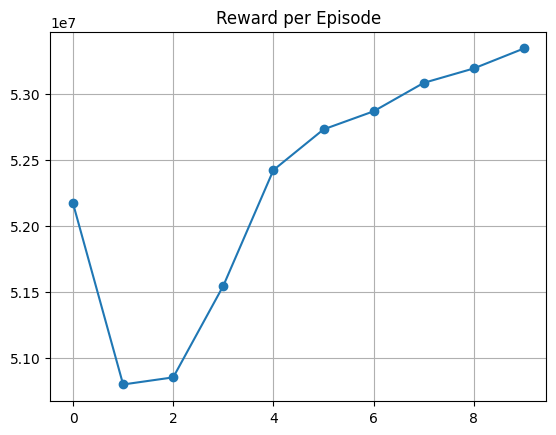

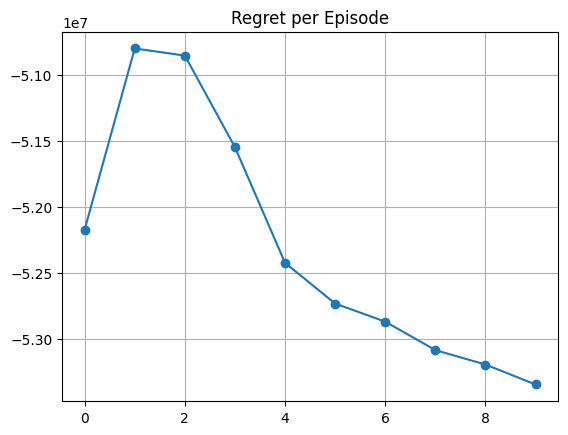

In [ ]:
train_agent(resume=True)   # resumes if a checkpoint exists, else starts fresh

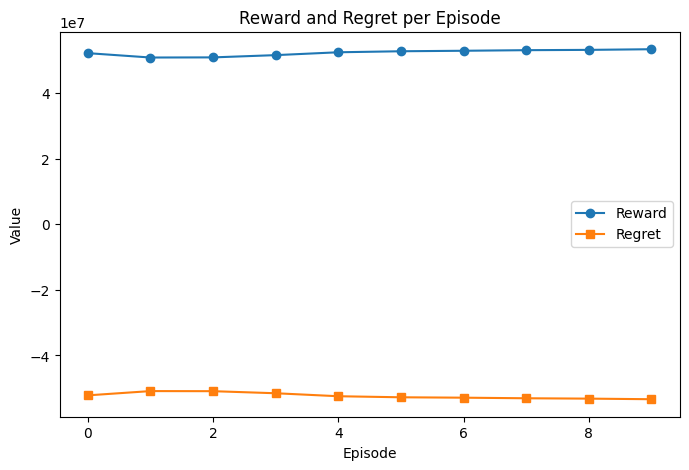

In [ ]:
import matplotlib.pyplot as plt

# Episodes
x = list(range(10))

# ≈ Values read from your figures (in 1e7 scale)
y_reward = [
    5.215e7, 5.082e7, 5.086e7, 5.155e7, 5.242e7,
    5.273e7, 5.288e7, 5.306e7, 5.315e7, 5.335e7
]

y_regret = [
   -5.218e7, -5.088e7, -5.091e7, -5.154e7, -5.245e7,
   -5.277e7, -5.289e7, -5.307e7, -5.318e7, -5.336e7
]

# Plot both
plt.figure(figsize=(8, 5))
plt.plot(x, y_reward, marker='o', label='Reward')
plt.plot(x, y_regret, marker='s', label='Regret')

# Labels & Legend
plt.title("Reward and Regret per Episode")
plt.xlabel("Episode")
plt.ylabel("Value")
plt.legend()
plt.grid(False)  # no grid lines

plt.show()


In [ ]:
import os, glob

DRIVE_ROOT = "/content/drive/MyDrive"
CKPT_DIR = os.path.join(DRIVE_ROOT, "checkpoints") if os.path.isdir(DRIVE_ROOT) else "./checkpoints"
METRICS_LIVE = os.path.join(CKPT_DIR, "run_metrics_live.csv")

def purge_training_state():
    if os.path.isdir(CKPT_DIR):
        for f in glob.glob(os.path.join(CKPT_DIR, "ckpt_ep*.pt")):
            try: os.remove(f); print("🗑️ deleted:", f)
            except Exception as e: print("⚠️ could not delete", f, "→", e)
    for f in [METRICS_LIVE, "run_metrics.csv"]:
        if os.path.exists(f):
            try: os.remove(f); print("🗑️ deleted:", f)
            except Exception as e: print("⚠️ could not delete", f, "→", e)
    os.makedirs(CKPT_DIR, exist_ok=True)
    print("✅ fresh start ready in:", CKPT_DIR)

purge_training_state()


🗑️ deleted: /content/drive/MyDrive/checkpoints/ckpt_ep0000_step00011711.pt
🗑️ deleted: /content/drive/MyDrive/checkpoints/ckpt_ep0001_step00023422.pt
🗑️ deleted: /content/drive/MyDrive/checkpoints/ckpt_ep0002_step00035133.pt
🗑️ deleted: /content/drive/MyDrive/checkpoints/run_metrics_live.csv
🗑️ deleted: run_metrics.csv
✅ fresh start ready in: /content/drive/MyDrive/checkpoints
